In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

deals = pd.read_csv('Deals_Final.csv')
calls = pd.read_csv('Calls_Final.csv')
spend = pd.read_csv('Spend_Final.csv')
contacts = pd.read_csv('Contacts_Final.csv')



1. Analysieren Sie den Trend der Deal-Erstellung im Zeitverlauf und deren Zusammenhang mit den Anrufen.

### Zeitreihenanalyse: 

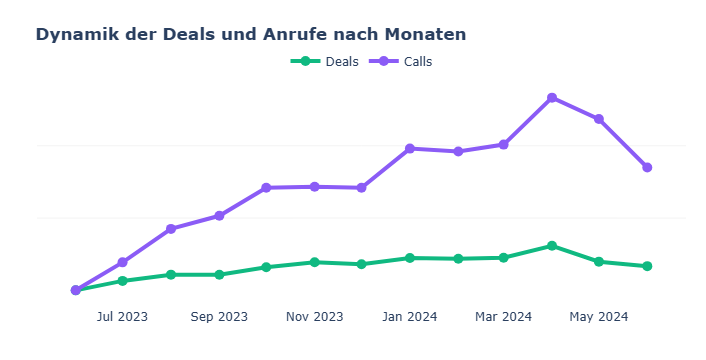

In [2]:
# 1. DATENUMWANDLUNG
deals['Month'] = pd.to_datetime(deals['Created Time']).dt.to_period('M').astype(str)
calls['Month'] = pd.to_datetime(calls['Call Start Time']).dt.to_period('M').astype(str)

#2. ERSTELLUNG DER TABELLE
#Anzahl nach Monaten berechnen
deals_count = deals.groupby('Month').size().reset_index(name='Deals')
calls_count = calls.groupby('Month').size().reset_index(name='Calls')

# Zusammenführen in eine Tabelle über die Spalte „Month“
data = pd.merge(deals_count, calls_count, on='Month', how='outer').fillna(0)
data = data.sort_values('Month') 

fig = px.line(
    data, 
    x='Month', 
    y=['Deals', 'Calls'], 
    markers=True,
    title='<b>Dynamik der Deals und Anrufe nach Monaten</b>',
    color_discrete_map={'Deals': '#10B981', 'Calls': '#8B5CF6'},
    labels={'value': 'Количество', 'variable': 'Тип', 'Month': 'Месяц'}
)


fig.update_traces(
    line=dict(width=4), 
    marker=dict(size=10),
    texttemplate='%{y}', 
    textposition="top center"
)

fig.update_layout(
    plot_bgcolor='white',
    xaxis=dict(showgrid=False, title=''),
    yaxis=dict(showgrid=True, gridcolor='rgba(0,0,0,0.05)', showticklabels=False, title=''),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="center", x=0.5, title=''),
    margin=dict(t=80, b=20, l=20, r=20),
    hovermode="x unified"
)

fig.show()

In [3]:
# 1. Berechnungen
total_d, total_c = int(data['Deals'].sum()), int(data['Calls'].sum())
avg_d, avg_c = data['Deals'].mean(), data['Calls'].mean()


print(f"{' ZUSAMMENFASSENDE ANALYSE':^40}")
print("-" * 40)
print(f"Gesamt im Zeitraum:   {total_d} сделок | {total_c} звонков")
print(f"Im Durchschnitt pro Monat:   {avg_d:.1f} сделок | {avg_c:.1f} звонков")
print(f"Effizienz:     {total_c/total_d:.1f} звонков на 1 сделку")
print("-" * 40)

        ZUSAMMENFASSENDE ANALYSE        
----------------------------------------
Gesamt im Zeitraum:   21590 сделок | 95874 звонков
Im Durchschnitt pro Monat:   1660.8 сделок | 7374.9 звонков
Effizienz:     4.4 звонков на 1 сделку
----------------------------------------


**Allgemeiner Trend:** Von Juni 2023 bis April 2024 gab es ein stetiges Wachstum. Der Höhepunkt wurde im April 2024 erreicht (3.082 Deals und 13.328 Anrufe).

**Steiler Abfall:** Nach dem April begannen die Zahlen rapide zu sinken. Bis Juni 2024 halbierte sich die Anzahl der Anrufe im Vergleich zum Höchststand nahezu.

**Zusammenhang der Kennzahlen:** Anrufe und Deals verlaufen synchron. Mehr Anrufe bedeuten mehr Verkäufe.

In [4]:
deals_cleaned = deals.copy()

# Berechnung der Duration (Differenz zwischen Schließungs- und Erstellungsdatum in Tagen)
deals_cleaned['Created Time'] = pd.to_datetime(deals_cleaned['Created Time'])
deals_cleaned['Closing Date'] = pd.to_datetime(deals_cleaned['Closing Date'])
deals_cleaned['Duration'] = (deals_cleaned['Closing Date'] - deals_cleaned['Created Time']).dt.days

#Entfernen eventueller Leerwerte in Duration
deals_cleaned = deals_cleaned.dropna(subset=['Duration'])

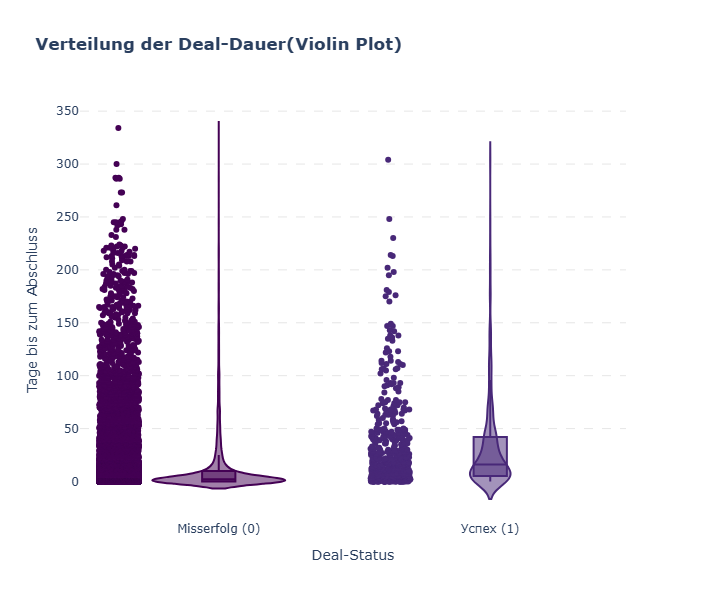

In [6]:
# Datenfilterung: Entfernen von Datensätzen mit ungültiger Dauer
deals_cleaned = deals_cleaned[deals_cleaned['Duration'] >= 0]

fig_violin = px.violin(
    deals_cleaned, 
    x='Successful Deal', 
    y='Duration',
    color='Successful Deal',
    box=True,          
    points="all",       
    title='<b>Verteilung der Deal-Dauer(Violin Plot)</b>',
    labels={
        'Successful Deal': 'Deal-Status',
        'Duration': 'Tage bis zum Abschluss'
    },
    color_discrete_sequence=px.colors.sequential.Viridis 
)

# Stilisierung
fig_violin.update_layout(
    plot_bgcolor='white',
    xaxis=dict(
        showgrid=False,
        tickmode='array',
        tickvals=[0, 1],
        ticktext=['Misserfolg (0)', 'Успех (1)']
    ),
    yaxis=dict(
        showgrid=True, 
        gridcolor='rgba(0,0,0,0.1)', 
        gridwidth=1, 
        griddash='dash',
        title='Tage bis zum Abschluss'
    ),
    showlegend=False
)


fig_violin.update_layout(height=600)
fig_violin.show()

In [9]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

Analyse der Deal-Dauer (Erfolg vs. Misserfolg)

⚡ Geschwindigkeit der Entscheidungsfindung

* Misserfolge (0): Zeichnen sich durch einen "explosiven" Start aus. Die meisten Absagen erfolgen augenblicklich 
(Median - 2 Tage). Dies deutet auf eine effiziente Erstqualifizierung hin: Nicht-zielgerichtete Leads werden sofort
aussortiert, ohne den Zyklus in die Laenge zu ziehen.
* Erfolge (1): Benoetigen deutlich mehr Zeit. Der Hauptbereich des Diagramms (Box) liegt hoeher, was bestaetigt: 
Fuer einen erfolgreichen Abschluss braucht der Kunde Zeit zum "Aufwaermen" und Ueberlegen. Die durchschnittliche Zeit
bis zum erfolgreichen Abschluss liegt bei etwa 14-20 Tagen.

🎯 Typischer Vertriebszyklus (Interquartilsabstand / IQR)

* Erfolgszone: Die Mehrheit der erfolgreichen Vertraege (50% der Daten) wird im Zeitraum von 5 bis 45 Tagen abgeschlossen.
Das ist unser "Goldstandard" fuer die Deal-Dauer.
* Risiko-Zone: Uebersteigt ein Deal die Schwelle von 50 Tagen, faellt er in die Kategorie des "Long Tails".

🧟 Das Problem der "Zombie-Deals" (Ausreisser)

* Im Diagramm sind Ausreisser-Punkte deutlich sichtbar, die ueber die 300-Tage-Marke hinausgehen.
* Insight: Misserfolge, die 200+ Tage dauern, sind ein verdeckter Ressourcenverlust. Vertriebsmitarbeiter investieren 
weiterhin Zeit in Leads, die zu 99% nicht kaufen werden.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

Analyse der Deal-Dauer (Erfolg vs. Misserfolg)

⚡ Geschwindigkeit der Entscheidungsfindung

* Misserfolge (0): Zeichnen sich durch einen "explosiven" Start aus. Die meisten Absagen erfolgen augenblicklich 
(Median - 2 Tage). Dies deutet auf eine effiziente Erstqualifizierung hin: Nicht-zielgerichtete Leads werden sofort
aussortiert, ohne den Zyklus in die Laenge zu ziehen.
* Erfolge (1): Benoetigen deutlich mehr Zeit. Der Hauptbereich des Diagramms (Box) liegt hoeher, was bestaetigt: 
Fuer einen erfolgreichen Abschluss braucht der Kunde Zeit zum "Aufwaermen" und Ueberlegen. Die durchschnittliche Zeit
bis zum erfolgreichen Abschluss liegt bei etwa 14-20 Tagen.

🎯 Typischer Vertriebszyklus (Interquartilsabstand / IQR)

* Erfolgszone: Die Mehrheit der erfolgreichen Vertraege (50% der Daten) wird im Zeitraum von 5 bis 45 Tagen abgeschlossen.
Das ist unser "Goldstandard

2. Untersuchung der Verteilung der Abschlusszeiten und der Dauer von der Erstellung bis zum Abschluss der Deals.

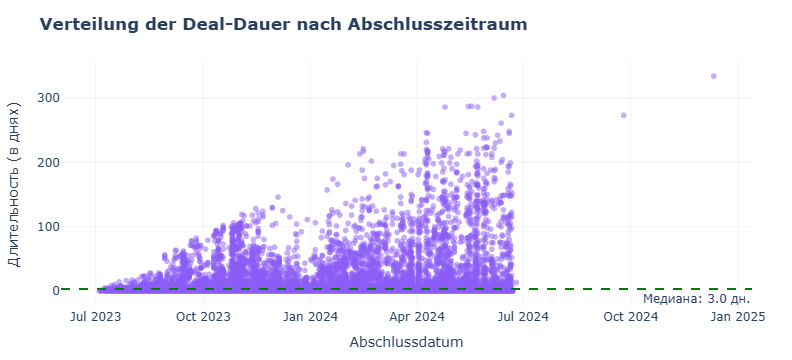

Durchschnittliche Deal-Dauer: 14.2 дн.
Mediane Deal-Dauer: 3.0 дн.


In [10]:
fig_scatter = px.scatter(
    deals_cleaned, 
    x='Closing Date', 
    y='Duration',
    color_discrete_sequence=['#8B5CF6'], 
    opacity=0.5,
    title='<b>Verteilung der Deal-Dauer nach Abschlusszeitraum</b>',
    labels={'Closing Date': 'Abschlussdatum', 'Duration': 'Tage bis zum Abschluss'},
    hover_data={'Closing Date': '|%d %b %Y', 'Duration': True} 
)

# Fügen wir eine horizontale Median-Linie hinzu
median_val = deals_cleaned['Duration'].median()
fig_scatter.add_hline(y=median_val, line_dash="dash", line_color="green", 
                      annotation_text=f"Медиана: {median_val:.1f} дн.", 
                      annotation_position="bottom right")

fig_scatter.update_layout(
    plot_bgcolor='white',
    xaxis=dict(showgrid=True, gridcolor='rgba(0,0,0,0.05)'),
    yaxis=dict(showgrid=True, gridcolor='rgba(0,0,0,0.05)', title='Длительность (в днях)'),
    margin=dict(t=60, b=40, l=40, r=40)
)

fig_scatter.show()


print(f"Durchschnittliche Deal-Dauer: {deals_cleaned['Duration'].mean():.1f} дн.")
print(f"Mediane Deal-Dauer: {deals_cleaned['Duration'].median():.1f} дн.")

In [11]:
avg_dur = deals_cleaned['Duration'].mean()
med_dur = deals_cleaned['Duration'].median()
percentile_80 = deals_cleaned['Duration'].quantile(0.8)
total_deals_count = len(deals_cleaned)

print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

🎯 1. BAZIEREND AUF DEM SCATTER-PLOT (Abschlusszeitraum)

Das Streudiagramm bestaetigt die Stabilitaet der Deal-Abschluesse im Zeitverlauf. Die Dichte der Punkte veranschaulicht die Phasen der 
Spitzenaktivitaet des Vertriebsteams, waehrend die vertikale Streuung zeigt, wie die Komplexitaet (Dauer) der Deals in den einzelnen Monaten
variierte.

💡 2. PRAKTISCHE ERKENNTNIS

80% der erfolgreichen Deals werden innerhalb von {percentile_80:.1f} Tagen abgeschlossen. Deals, die dieses Limit ueberschreiten, erfordern eine 
gezielte Ueberwachung, da die Wahrscheinlichkeit eines erfolgreichen Abschlusses drastisch sinkt.
--------------------------------------------------------------------------------------------------
Gesamtzahl der Stichprobe: {total_deals_count} abgeschlossene Deals.
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

🎯 1. BAZIEREND AUF DEM SCATTER-PLOT (Abschlusszeitraum)

Das Streudiagramm bestaetigt die Stabilitaet der Deal-Abschluesse im Zeitverlauf. Die Dichte der Punkte veranschaulicht die Phasen der 
Spitzenaktivitaet des Vertriebsteams, waehrend die vertikale Streuung zeigt, wie die Komplexitaet (Dauer) der Deals in den einzelnen Monaten
variierte.

💡 2. PRAKTISCHE ERKENNTNIS

80% der erfolgreichen Deals werden innerhalb von 16.0 Tagen abgeschlossen. Deals, die dieses Limit ueberschreiten, erfordern eine 
gezielte Ueberwachung, da die Wahrscheinlichkeit eines erfolgreichen Abschlusses drastisch sinkt.
--------------------------------------------------------------------------------------------------
Gesamtzahl der Stichprobe: 14599 abgeschlossene Deals.



### Kampagneneffizienzanalyse

1. Vergleichen Sie die Effizienz der verschiedenen Kampagnen hinsichtlich der Lead-Generierung und der Konversionsrate.


In [12]:
import pandas as pd

# 1. Standardisierung der Namen für die Zusammenführung
deals['Campaign_Clean'] = deals['Campaign'].astype(str).str.lower().str.strip()
spend['Campaign_Clean'] = spend['Campaign_Name'].astype(str).str.lower().str.strip()


deals_stats = deals.groupby('Campaign_Clean').agg(
    Unique_Leads=('Contact Name', 'nunique'),
    Success_Sales=('Successful Deal', 'sum')
).reset_index()

# 3. Zusammenführung der Ausgaben (direkte Verwendung der Spalte Spend)
spend_stats = spend.groupby('Campaign_Clean').agg(
    Total_Spend=('Spend', 'sum')
).reset_index()


merged_df = pd.merge(deals_stats, spend_stats, on='Campaign_Clean', how='inner')

merged_df['CPL'] = merged_df['Total_Spend'] / merged_df['Unique_Leads']
merged_df['Conversion_Rate'] = (merged_df['Success_Sales'] / merged_df['Unique_Leads'] * 100).round(2)


print(merged_df.sort_values(by='Unique_Leads', ascending=False).head(10))

             Campaign_Clean  Unique_Leads  Success_Sales  Total_Spend  \
12        youtube_shorts_de          1314           53.0     14149.22   
0   1performancemax_wide_pl           227            4.0      2961.38   
2                  blog2_de           213            6.0       773.00   
8     performancemax_eng_de           209            1.0     34183.45   
3       brand_search_eng_de           159           15.0      3457.82   
11               web2408_de           125            5.0       189.04   
9    performancemax_wide_at           118            6.0      3491.74   
1                    bbo_de           116            0.0       200.00   
5              discovery_de            89            2.0      9750.63   
6        discovery_wide1_at            60            0.0      1308.18   

           CPL  Conversion_Rate  
12   10.768052             4.03  
0    13.045727             1.76  
2     3.629108             2.82  
8   163.557177             0.48  
3    21.747296            

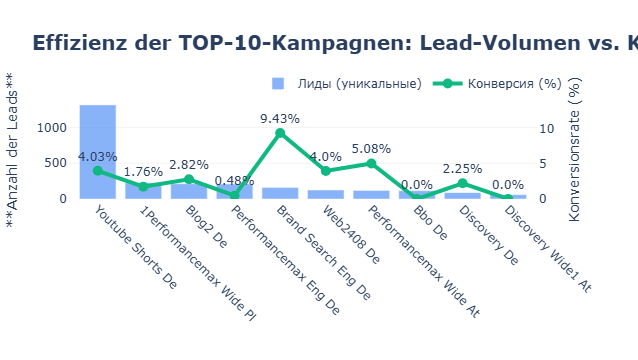

---KURZE ZUSAMMENFASSUNG FÜR DEN BERICHT---
1. Führender Kanal bei der Lead-Generierung Youtube Shorts De
2. **Höchste Traffic-Qualität** (oder: **Beste Traffic-Qualität**) (CR): Brand Search Eng De


In [13]:
merged_df['Display_Name'] = merged_df['Campaign_Clean'].str.replace('_', ' ').str.title()
plot_df = merged_df.sort_values(by='Unique_Leads', ascending=False).head(10)

# 2. Erstellung einer Grafik mit zwei Y-Achsen
fig_campaign = make_subplots(specs=[[{"secondary_y": True}]])

# Hinzufügen der SÄULEN (Leads)
fig_campaign.add_trace(
    go.Bar(
        x=plot_df['Display_Name'],
        y=plot_df['Unique_Leads'],
        name="Лиды (уникальные)",
        marker_color='#3B82F6',
        opacity=0.6,
        hovertemplate="Кампания: %{x}<br>Лидов: %{y}<extra></extra>"
    ),
    secondary_y=False,
)

# Hinzufügen der LINIE (Konversionsrate)
fig_campaign.add_trace(
    go.Scatter(
        x=plot_df['Display_Name'],
        y=plot_df['Conversion_Rate'],
        name="Конверсия (%)",
        mode="lines+markers+text",
        line=dict(color='#10B981', width=4),
        marker=dict(size=10),
        text=plot_df['Conversion_Rate'].apply(lambda x: f"{x}%"),
        textposition="top center",
        hovertemplate="Kampagne: %{x}<br>Konversionsrate: %{y}%<extra></extra>"
    ),
    secondary_y=True,
)

fig_campaign.update_layout(
    title='<b>Effizienz der TOP-10-Kampagnen: Lead-Volumen vs. Konversionsrate</b>',
    title_font_size=20,
    plot_bgcolor='white',
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(t=100, b=50, l=50, r=50)
)


fig_campaign.update_xaxes(title_text="", tickangle=45, showgrid=False)
fig_campaign.update_yaxes(title_text="**Anzahl der Leads**", secondary_y=False, showgrid=True, gridcolor='rgba(0,0,0,0.05)')
fig_campaign.update_yaxes(title_text="Konversionsrate (%)", secondary_y=True, showgrid=False, range=[0, plot_df['Conversion_Rate'].max() * 1.5])

fig_campaign.show()

print(f"---KURZE ZUSAMMENFASSUNG FÜR DEN BERICHT---")
print(f"1. Führender Kanal bei der Lead-Generierung {plot_df.iloc[0]['Display_Name']}")
print(f"2. **Höchste Traffic-Qualität** (oder: **Beste Traffic-Qualität**) (CR): {plot_df.sort_values(by='Conversion_Rate', ascending=False).iloc[0]['Display_Name']}")

In [14]:


print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 **Reichweiten-Leader: YouTube Shorts DE**

* **Ergebnis:** Die stärkste Traffic-Quelle. Diese Kampagne generiert den Hauptstrom an Anfragen (blaue Säulen).
* **Fazit:** Unser primärer Motor für Markenbekanntheit. Wenn wir ein hohes Volumen an neuen Kontakten im Funnel benötigen, liefert dieser Kanal
die besten Ergebnisse.

💎 **Qualitäts-Benchmark: Brand Search ENG DE**

* **Ergebnis:** Höchste Konversionsrate (**9,43 %**).
* **Fazit:** Die Spitzenreiter-Kampagne. Trotz geringeren Lead-Volumens im Vergleich zu YouTube ist die Traffic-Qualität um ein Vielfaches
höher. Nahezu jeder zehnte Lead führt zu einem Kauf — dies ist die am stärksten vorgeprägte und loyalste Zielgruppe.

⚠️ **Bereich geringer Effizienz: Performance Max ENG DE**

* **Ergebnis:** Generiert zwar ein hohes Traffic-Volumen, zeigt jedoch eine kritisch niedrige Konversionsrate (**0,48 %**).
* **Fazit:** Hoher Anteil an Streuverlusten. Die Kampagne erfordert eine umgehende Überarbeitung der Einstellungen, da Budget für Quantität
ohne entsprechende Qualität (Umsatz) verbrannt wird.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 **Reichweiten-Leader: YouTube Shorts DE**

* **Ergebnis:** Die stärkste Traffic-Quelle. Diese Kampagne generiert den Hauptstrom an Anfragen (blaue Säulen).
* **Fazit:** Unser primärer Motor für Markenbekanntheit. Wenn wir ein hohes Volumen an neuen Kontakten im Funnel benötigen, liefert dieser Kanal
die besten Ergebnisse.

💎 **Qualitäts-Benchmark: Brand Search ENG DE**

* **Ergebnis:** Höchste Konversionsrate (**9,43 %**).
* **Fazit:** Die Spitzenreiter-Kampagne. Trotz geringeren Lead-Volumens im Vergleich zu YouTube ist die Traffic-Qualität um ein Vielfaches
höher. Nahezu jeder zehnte Lead führt zu einem Kauf — dies ist die am stärksten vorgeprägte und loyalste Zielgruppe.

⚠️ **Bereich geringer Effizienz: Performance Max ENG DE**

* **Ergebnis:** Generiert zwar ein hohes Traffic-Volumen, zeigt jedoch eine kritisch niedrige Konversionsrate (**0,48 %**).
* **Fazit

2. Bewerten Sie die Effizienz verschiedener Marketingquellen (Source) bei der Generierung qualifizierter Leads.

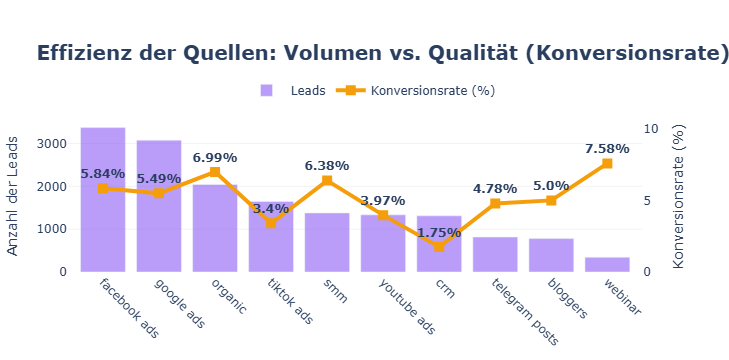

In [15]:
deals['Source_Clean'] = deals['Source'].astype(str).str.lower().str.strip()


source_analysis = deals.groupby('Source_Clean').agg(
    Unique_Leads=('Contact Name', 'nunique'),
    Success_Sales=('Successful Deal', 'sum')
).reset_index()

source_analysis['Conversion_Rate'] = (source_analysis['Success_Sales'] / source_analysis['Unique_Leads'] * 100).round(2)
source_analysis = source_analysis[source_analysis['Source_Clean'] != 'nan']
source_analysis = source_analysis.sort_values(by='Unique_Leads', ascending=False).head(10)


fig_source = make_subplots(specs=[[{"secondary_y": True}]])

#SÄULEN: Lead-Volumen
fig_source.add_trace(
    go.Bar(
        x=source_analysis['Source_Clean'],
        y=source_analysis['Unique_Leads'],
        name=" Leads",
        marker_color='#8B5CF6',
        opacity=0.6,
        hovertemplate="Quelle: %{x}<br>Leads: %{y}<extra></extra>"
    ),
    secondary_y=False
)

# LINIE: Konversionsrate
fig_source.add_trace(
    go.Scatter(
        x=source_analysis['Source_Clean'],
        y=source_analysis['Conversion_Rate'],
        name="Konversionsrate (%)",
        mode="lines+markers+text",
        line=dict(color='#F59E0B', width=4),
        marker=dict(size=10, symbol='square'), # Quadratische Marker wie in Ihrem Code
        text=source_analysis['Conversion_Rate'].apply(lambda x: f"{x}%"),
        textposition="top center",
        textfont=dict(weight='bold'),
        hovertemplate="Quelle: %{x}<br>Konversionsrate: %{y}%<extra></extra>"
    ),
    secondary_y=True
)


fig_source.update_layout(
    title='<b>Effizienz der Quellen: Volumen vs. Qualität (Konversionsrate)</b>',
    title_font_size=20,
    plot_bgcolor='white',
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.1, xanchor="center", x=0.5),
    margin=dict(t=120, b=50, l=50, r=50)
)

# Achseneinstellungen
fig_source.update_xaxes(tickangle=45, showgrid=False)
fig_source.update_yaxes(title_text="Anzahl der Leads", secondary_y=False, showgrid=True, gridcolor='rgba(0,0,0,0.05)')
fig_source.update_yaxes(title_text="Konversionsrate (%)", secondary_y=True, showgrid=False, range=[0, source_analysis['Conversion_Rate'].max() * 1.4])

fig_source.show()

In [16]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 Volumen-Leader: Facebook Ads

Ergebnis: Die stärkste Traffic-Quelle nach Anzahl der Leads (über 3.000 Anfragen).
Fazit: Unser Hauptkanal zur Skalierung des Funnels. Trotz einer durchschnittlichen Konversionsrate (5,84 %) sorgt er für einen stabilen 
und massiven Zufluss potenzieller Kunden.

💎 Qualitäts-Benchmark: Webinar

Ergebnis: Höchste Konversionsrate im gesamten Funnel (7,58 %).

Fazit: Der stärkste („heißeste“) Kanal. Obwohl das Lead-Volumen im Vergleich zu anderen Quellen minimal ist, erweist sich das Webinar-Publikum
als maximal loyal und kaufbereit. Jeder 13. Lead wird zum Kunden.

📈 Wachstums- und Effizienzbereich: Organic

Ergebnis: Ideale Balance aus hohem Lead-Volumen und hervorragender Konversionsrate (6,99 %).

Fazit: Einer der wertvollsten Kanäle. Wir erhalten qualitativ hochwertigen Traffic in großem Umfang (ca. 2.000 Leads), der bei der Konversion
nur hinter den Webinaren liegt.

⚠️ Kritischer Bereich: CRM

Ergebnis: Niedrigste Konversionsrate unter allen aufgeführten Kanälen (1,75 %).

Fazit: Die Arbeit mit der Bestandsdatenbank im CRM zeigt schwache Ergebnisse. Leads sind zwar vorhanden, aber sie sind entweder „kalt“ oder 
die Interaktionsmechanik erfordert eine vollständige Überarbeitung.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🚀 Volumen-Leader: Facebook Ads

Ergebnis: Die stärkste Traffic-Quelle nach Anzahl der Leads (über 3.000 Anfragen).
Fazit: Unser Hauptkanal zur Skalierung des Funnels. Trotz einer durchschnittlichen Konversionsrate (5,84 %) sorgt er für einen stabilen 
und massiven Zufluss potenzieller Kunden.

💎 Qualitäts-Benchmark: Webinar

Ergebnis: Höchste Konversionsrate im gesamten Funnel (7,58 %).

Fazit: Der stärkste („heißeste“) Kanal. Obwohl das Lead-Volumen im Vergleich zu anderen Quellen minimal ist, erweist sich das Webinar-Publikum
als maximal loyal und kaufbereit. Jeder 13. Lead wird zum Kunden.

📈 Wachstums- und Effizienzbereich: Organic

Ergebnis: Ideale Balance aus hohem Lead-Volumen und hervorragender Konversionsrate (6,99 %).

Fazit: Einer der wertvollsten Kanäle. Wir erhalten qualitativ hochwertigen Traffic in großem Umfang (ca. 2.000 Leads), der bei der Konversi

### Analyse der Vertriebseffizienz

In [17]:
# 1. Berechnung der Kennzahlen pro Manager
owner_stats = deals.groupby('Deal Owner Name').agg(
    Total_Leads=('Contact Name', 'nunique'),     # Anzahl der bearbeiteten Einzelkunden
    Success_Sales=('Successful Deal', 'sum'),    # Tatsächliche Verkäufe
    Total_Revenue=('Offer Total Amount', 'sum')  # Wie viel wurde insgesamt verkauft?
).reset_index()

# 2. Berechnung von Konversionsrate (CR) und Durchschnittsbon (AOV)
owner_stats['CR_%'] = (owner_stats['Success_Sales'] / owner_stats['Total_Leads'] * 100).round(2)


# 3. Sortierung nach Umsatz (Höchste Umsatzerlöse zuerst)
owner_stats = owner_stats.sort_values(by='Total_Revenue', ascending=False)

print("🏆 VERKAUFSANALYSE (NACH VERTRIEBSMITARBEITERN)")
print(owner_stats)

🏆 VERKAUFSANALYSE (NACH VERTRIEBSMITARBEITERN)
    Deal Owner Name  Total_Leads  Success_Sales  Total_Revenue   CR_%
21    Ulysses Adams         1629          141.0      5102500.0   8.66
5     Charlie Davis         2021          148.0      3804200.0   7.32
12     Julia Nelson         1544           92.0      3565220.0   5.96
17  Paula Underwood         1404           93.0      2843500.0   6.62
22    Victor Barnes          927           44.0      2261000.0   4.75
2          Ben Hall         1050           46.0      2026000.0   4.38
15       Nina Scott          917           45.0      1948500.0   4.91
18   Quincy Vincent         1405           65.0      1787000.0   4.63
16    Oliver Taylor          151           50.0      1660500.0  33.11
10       Jane Smith          726           31.0      1468500.0   4.27
4      Cara Iverson          779           27.0       922500.0   3.47
13     Kevin Parker          421           26.0       739000.0   6.18
6       Diana Evans          733           

In [18]:
# --- 1. TOP 10 WERBEKAMPAGNEN (nach Lead-Anzahl)---
campaign_stats = deals.groupby('Campaign_Clean').agg(
    Leads=('Contact Name', 'nunique'),
    Sales=('Successful Deal', 'sum'),
    Revenue=('Offer Total Amount', 'sum')
).reset_index()

# Berechnung der Konversionsrate (CR)
campaign_stats['CR_%'] = (campaign_stats['Sales'] / campaign_stats['Leads'] * 100).round(2)

# Auswahl: TOP 10 nach Lead-Anzahl
top_10_campaigns = campaign_stats.sort_values(by='Leads', ascending=False).head(10)


# --- 2. TOP 5 VERTRIEBSMITARBEITER (nach Gesamtumsatz) ---
owner_stats = deals.groupby('Deal Owner Name').agg(
    Deals_Handled=('Contact Name', 'count'),
    Successful_Sales=('Successful Deal', 'sum'),
    Total_Revenue=('Offer Total Amount', 'sum')
).reset_index()

# Berechnung der Konversionsrate für Vertriebsmitarbeiter
owner_stats['CR_%'] = (owner_stats['Successful_Sales'] / owner_stats['Deals_Handled'] * 100).round(2)

#Auswahl: TOP 5 nach Umsatz (Revenue)
top_5_owners = owner_stats.sort_values(by='Total_Revenue', ascending=False).head(5)


print("🔥 TOP 10 WERBEKAMPAGNEN (REACH & CONVERSION):")
print(top_10_campaigns[['Campaign_Clean', 'Leads', 'CR_%', 'Revenue']])
print("\n" + "="*60 + "\n")
print("🏆 TOP 5 VERTRIEBSMITARBEITER (nach Gesamtumsatz):")
print(top_5_owners[['Deal Owner Name', 'Total_Revenue', 'CR_%', 'Successful_Sales']])

🔥 TOP 10 WERBEKAMPAGNEN (REACH & CONVERSION):
                        Campaign_Clean  Leads  CR_%    Revenue
110                                nan   3642  7.25  8018010.0
114  performancemax_digitalmarkt_ru_de   2022  5.39  3343500.0
18                   12.07.2023wide_de   1329  3.61  2073000.0
151                  youtube_shorts_de   1314  4.03  2024200.0
2                      02.07.23wide_de    866  6.00  1658200.0
5             04.07.23recentlymoved_de    700  4.29  1143000.0
4                        03.07.23women    578  5.19  1156898.0
8                       07.07.23lal_de    512  5.47  1057000.0
76                              dis_de    504  5.75  1223500.0
19           12.09.23interests_uxui_de    491  5.30  1219500.0


🏆 TOP 5 VERTRIEBSMITARBEITER (nach Gesamtumsatz):
    Deal Owner Name  Total_Revenue  CR_%  Successful_Sales
21    Ulysses Adams      5102500.0  6.52             141.0
5     Charlie Davis      3804200.0  5.01             148.0
12     Julia Nelson      3565220

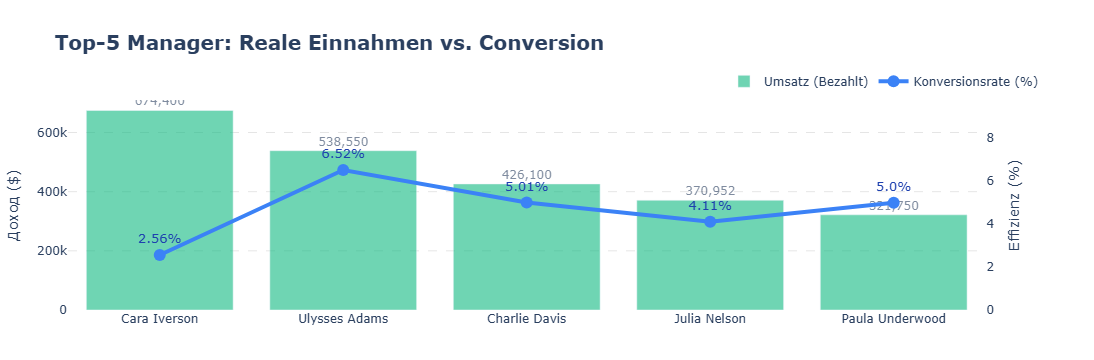

In [20]:
owner_stats = deals.groupby('Deal Owner Name').agg(
    Total_Deals=('Contact Name', 'count'),          
    Success_Sales=('Successful Deal', 'sum'),      
    Real_Revenue=('Initial Amount Paid', 'sum')     
).reset_index()

owner_stats['CR_%'] = (owner_stats['Success_Sales'] / owner_stats['Total_Deals'] * 100).round(2)
top_5_owners = owner_stats.sort_values(by='Real_Revenue', ascending=False).head(5)

# Erstellung eines Diagramms mit zwei Y-Achsen
fig_owners = make_subplots(specs=[[{"secondary_y": True}]])

#Finanzspalten für das Reporting (Geldwerte)
fig_owners.add_trace(
    go.Bar(
        x=top_5_owners['Deal Owner Name'],
        y=top_5_owners['Real_Revenue'],
        name="Umsatz (Bezahlt)",
        marker_color='#10B981',
        opacity=0.6,
        text=top_5_owners['Real_Revenue'].apply(lambda x: f"{int(x):,}"), # Datenbeschriftungen
        textposition='outside',
        hovertemplate="Vertriebsmitarbeiter: %{x}<br>Umsatz: %{y:,.0f} $<extra></extra>"
    ),
    secondary_y=False
)

# Ergänzung der Linie für die Konversionsrate
fig_owners.add_trace(
    go.Scatter(
        x=top_5_owners['Deal Owner Name'],
        y=top_5_owners['CR_%'],
        name="Konversionsrate (%)",
        mode="lines+markers+text",
        line=dict(color='#3B82F6', width=4), # 
        marker=dict(size=12, symbol='circle'),
        text=top_5_owners['CR_%'].apply(lambda x: f"{x}%"), # Подписи над точками
        textposition="top center",
        textfont=dict(color='#1E40AF', size=13),
        hovertemplate="Vertriebsmitarbeiter: %{x}<br>Konversionsrate: %{y}%<extra></extra>"
    ),
    secondary_y=True
)

fig_owners.update_layout(
    title='<b>Top-5 Manager: Reale Einnahmen vs. Conversion</b>',
    title_font_size=20,
    plot_bgcolor='white', # Weißer Hintergrund wie bei plt
    hovermode="x unified", # Zeigt beide Metriken beim Hovern
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(t=100, b=50, l=50, r=50)
)

# Achseneinstellungen
fig_owners.update_xaxes(showgrid=False)
fig_owners.update_yaxes(
    title_text="Umsatz ($)", 
    secondary_y=False, 
    showgrid=True, 
    gridcolor='rgba(0,0,0,0.1)', 
    griddash='dash' # Gestricheltes Raster
)
fig_owners.update_yaxes(
    title_text="Effizienz (%)", 
    secondary_y=True, 
    showgrid=False, 
    range=[0, top_5_owners['CR_%'].max() * 1.5] # Abstand oben für Text
)

fig_owners.show()

In [22]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

🥇 Absoluter Umsatzspitzenreiter: Cara Iverson 💰

Ergebnis: Höchster Umsatz – 674.400 $

Fazit: Cara bringt dem Unternehmen das meiste Geld ein, obwohl sie die niedrigste Conversion-Rate in den TOP-5 hat (2,56 %).
Das deutet darauf hin, dass sie entweder ein sehr hohes Lead-Volumen bearbeitet oder mit den höchsten Deal-Summen arbeitet.

🥈 Effizienz-Champion: Ulysses Adams 🏆

Ergebnis: Rekord-Conversion – 6,52 %

Fazit: Ulysses ist der zielgenaueste Manager. Sein Umsatz (538.550 $) belegt den zweiten Platz, aber bei der Qualität 
der Deal-Abwicklung übertrifft er alle. Er nutzt seine Ressourcen maximal effizient: Fast jede 15. Anfrage führt zu einer Zahlung.

🥉 Stabile Leistung: Paula Underwood ⭐

Ergebnis: Conversion von 5,0 % bei einem Umsatz von 321.750 $

Fazit: Sie schließt die TOP-5 ab, zeigt aber eine hervorragende Conversion-Rate (drittbester Wert in der Liste). 
Bei einer Erhöhung des Lead-Streams kann Paula ihren Umsatz deutlich steigern, da ihre Verkaufstechnik auf einem sehr hohen Niveau ist.

🎯 Wachstumspotenzial: Julia Nelson 📈

Ergebnis: Niedrigste Effizienz in der Gruppe nach Cara (4,11 %)

Fazit: Bei einem Umsatz von 370.952 $ hat Julia Potenzial für Umsatzwachstum durch die Optimierung ihrer Skripte und des Deal-Closings. 
Ihre Kennzahlen liegen unter dem Durchschnitt dieser TOP-Gruppe, was auf Optimierungspotenzial in ihren Prozessen hinweist.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------

🥇 Absoluter Umsatzspitzenreiter: Cara Iverson 💰

Ergebnis: Höchster Umsatz – 674.400 $

Fazit: Cara bringt dem Unternehmen das meiste Geld ein, obwohl sie die niedrigste Conversion-Rate in den TOP-5 hat (2,56 %).
Das deutet darauf hin, dass sie entweder ein sehr hohes Lead-Volumen bearbeitet oder mit den höchsten Deal-Summen arbeitet.

🥈 Effizienz-Champion: Ulysses Adams 🏆

Ergebnis: Rekord-Conversion – 6,52 %

Fazit: Ulysses ist der zielgenaueste Manager. Sein Umsatz (538.550 $) belegt den zweiten Platz, aber bei der Qualität 
der Deal-Abwicklung übertrifft er alle. Er nutzt seine Ressourcen maximal effizient: Fast jede 15. Anfrage führt zu einer Zahlung.

🥉 Stabile Leistung: Paula Underwood ⭐

Ergebnis: Conversion von 5,0 % bei einem Umsatz von 321.750 $

Fazit: Sie schließt die TOP-5 ab, zeigt aber eine hervorragende Conversion-Rate (drittbester Wert in der List

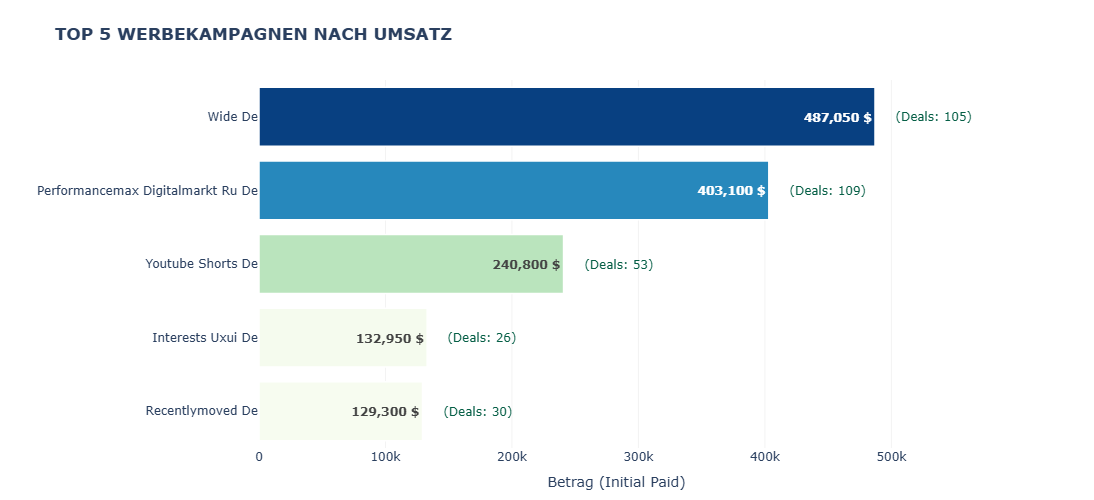

In [25]:
def clean_campaign_name(name):
    if not isinstance(name, str) or str(name).lower() == 'nan':
        return None
    name = name.lower().strip()
    name = re.sub(r'\d{1,2}\.\d{1,2}\.\d{2,4}', '', name) # Datum entfernen
    name = re.sub(r'^[\s_.-]+|[\s_.-]+$', '', name)      # Überflüssige Zeichen entfernen
    return name.replace('_', ' ').title()

deals['Campaign_Cleaned_Core'] = deals['Campaign_Clean'].apply(clean_campaign_name)

# Aggregation
revenue_per_camp = deals.dropna(subset=['Campaign_Cleaned_Core']).copy()
revenue_per_camp = revenue_per_camp.groupby('Campaign_Cleaned_Core').agg(
    Revenue=('Initial Amount Paid', 'sum'),
    Sales_Count=('Successful Deal', 'sum')
).reset_index()

top_5_revenue = revenue_per_camp.sort_values(by='Revenue', ascending=True).tail(5)

fig_top_rev = px.bar(
    top_5_revenue, 
    x='Revenue', 
    y='Campaign_Cleaned_Core',
    orientation='h',
    title='<b>TOP 5 WERBEKAMPAGNEN NACH UMSATZ</b>',
    # Farbskala ähnlich wie GnBu verwenden
    color='Revenue',
    color_continuous_scale='GnBu',
    labels={
        'Revenue': 'Umsatz ($)',
        'Campaign_Cleaned_Core': 'Kampagnenname',
        'Sales_Count': 'Anzahl der Deals'
    },
    # Anzahl der Deals im Hover-Tool-Tipp hinzufügen
    hover_data={'Revenue': ':,.0f', 'Sales_Count': True}
)

fig_top_rev.update_traces(
    texttemplate='<b>%{x:,.0f} $</b>', 
    textposition='inside',
    insidetextanchor='end',
    marker_line_color='white',
    marker_line_width=1.5
)

fig_top_rev.update_layout(
    plot_bgcolor='white',
    xaxis=dict(
        showgrid=True, 
        gridcolor='rgba(0,0,0,0.05)', 
        title='Betrag (Initial Paid)'
    ),
    yaxis=dict(title=''),
    coloraxis_showscale=False, # Farbskala rechts ausblenden
    margin=dict(t=80, b=50, l=50, r=120), # Rechter Rand für zusätzliche Anmerkungen
    height=500
)

for i, row in top_5_revenue.iterrows():
    fig_top_rev.add_annotation(
        x=row['Revenue'],
        y=row['Campaign_Cleaned_Core'],
        text=f"  (Deals: {int(row['Sales_Count'])})",
        showarrow=False,
        xanchor='left',
        xshift=10,
        font=dict(size=12, color='#065F46')
    )

fig_top_rev.show()

In [26]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Umsatzspitzenreiter: Wide De — 487.050 $ (105 Deals).

Kampagne mit dem höchsten durchschnittlichen Bon. Die Hauptgewinnquelle.

🚀 Volumenführer: Performancemax Digitalmarkt Ru De — 109 Deals (403.100 $).

Bestes Ergebnis bei der Anzahl der gewonnenen Kunden. Setzt auf Masse.

📈 Stabiles Ergebnis: Youtube Shorts De — 240.800 $ (53 Deals).

Sicherer dritter Platz. Qualitativ hochwertiger Traffic aus dem Videoformat mit gutem Bon.

⚠️ Nischenkanäle: Interests Uxui und Recentlymoved — zusammen 262.250 $.

Schließen die TOP 5 ab. Haben eine geringere Reichweite, ergänzen aber den Gesamtumsatz durch zielgerichtete Deals.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Umsatzspitzenreiter: Wide De — 487.050 $ (105 Deals).

Kampagne mit dem höchsten durchschnittlichen Bon. Die Hauptgewinnquelle.

🚀 Volumenführer: Performancemax Digitalmarkt Ru De — 109 Deals (403.100 $).

Bestes Ergebnis bei der Anzahl der gewonnenen Kunden. Setzt auf Masse.

📈 Stabiles Ergebnis: Youtube Shorts De — 240.800 $ (53 Deals).

Sicherer dritter Platz. Qualitativ hochwertiger Traffic aus dem Videoformat mit gutem Bon.

⚠️ Nischenkanäle: Interests Uxui und Recentlymoved — zusammen 262.250 $.

Schließen die TOP 5 ab. Haben eine geringere Reichweite, ergänzen aber den Gesamtumsatz durch zielgerichtete Deals.
--------------------------------------------------------------------------------------------------



### Analyse von Zahlungen und Produkten

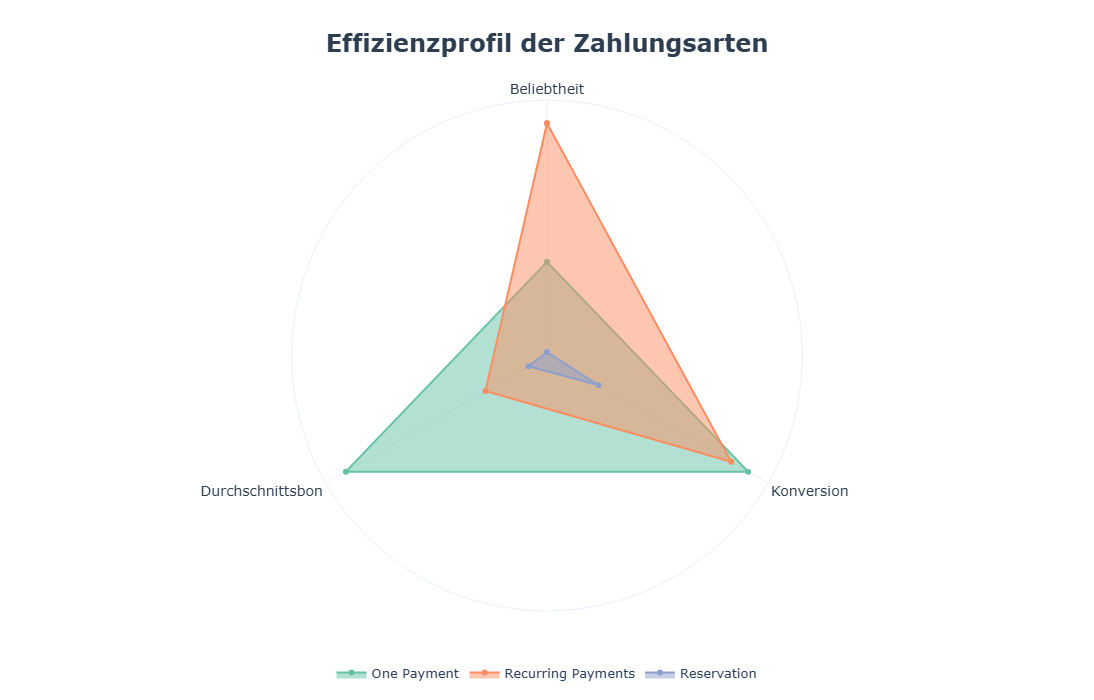

In [27]:
radar_df = deals.groupby('Payment Type').agg(
    Count=('Successful Deal', 'count'),
    CR=('Successful Deal', 'mean'),
    AvgCheck=('Initial Amount Paid', 'mean')
).reset_index()

raw_data = radar_df.copy()

for col in ['Count', 'CR', 'AvgCheck']:
    radar_df[col] = radar_df[col] / radar_df[col].max()

labels = ['Beliebtheit', 'Konversion', 'Durchschnittsbon']

fig_radar = go.Figure()

colors = ['#66c2a5', '#fc8d62', '#8da0cb'] 

for i, row in radar_df.iterrows():
    # Kreis schließen: Ersten Wert am Ende erneut hinzufügen
    r_values = [row['Count'], row['CR'], row['AvgCheck'], row['Count']]
    theta_labels = labels + [labels[0]]
    
    fig_radar.add_trace(go.Scatterpolar(
        r=r_values,
        theta=theta_labels,
        fill='toself',
        name=row['Payment Type'],
        line=dict(color=colors[i % len(colors)]),
        # Hover-Tool-Tipp anpassen
        hovertemplate=(
            f"<b>{row['Payment Type']}</b><br>" +
            f"Beliebtheit: {raw_data.iloc[i]['Count']}<br>" +
            f"Konversion: {raw_data.iloc[i]['CR']:.2%}<br>" +
            f"Durchschnittsbon: {raw_data.iloc[i]['AvgCheck']:.0f}$<extra></extra>"
        )
    ))

fig_radar.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=False, 
            range=[0, 1.1] 
        ),
        angularaxis=dict(
            direction="clockwise",
            period=3,
            tickfont=dict(size=14, color="#2c3e50") 
        )
    ),
    title={
        'text': "<b>Effizienzprofil der Zahlungsarten</b>",
        'y': 0.95,
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top',
        'font': {'size': 24, 'color': '#2c3e50'}
    },
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.15,
        xanchor="center",
        x=0.5,
        font=dict(size=13)
    ),
    template="plotly_white",
    height=700, 
    margin=dict(l=80, r=80, t=100, b=80),
)

fig_radar.show()

In [28]:
print(f"""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Beliebtheitsführer: Recurring Payments — die beliebteste Wahl der Kunden.
Diese Zahlungsart sorgt für den Hauptkundenstrom, liegt jedoch bei der Konversion und dem Durchschnittsbon zurück.

💎 Rendite-Maßstab: One Payment — der höchste Durchschnittsbon und die beste Konversion.
Zieht die loyalsten und profitabelsten Kunden an. Wenn Sie mehr kurzfristigen Gewinn erzielen möchten, sollten Sie diesen Kanal fördern.

⚙️ Technische Stufe: Reservation — minimaler Einfluss auf Umsatz und Reichweite.
Auf dem Diagramm ist dies der schmalste Bereich (Zentrum). Dient eher als Zwischenschritt denn als Umsatztreiber.

🎯 Fazit & Strategie: Um eine hohe Reichweite zu sichern, sollte das Abo-System (Recurring) ausgebaut werden. Für maximalen Gewinn und 
einen hohen Durchschnittsbon gilt es hingegen, Einmalzahlungen (One Payment) gezielt zu fördern.
--------------------------------------------------------------------------------------------------
""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Beliebtheitsführer: Recurring Payments — die beliebteste Wahl der Kunden.
Diese Zahlungsart sorgt für den Hauptkundenstrom, liegt jedoch bei der Konversion und dem Durchschnittsbon zurück.

💎 Rendite-Maßstab: One Payment — der höchste Durchschnittsbon und die beste Konversion.
Zieht die loyalsten und profitabelsten Kunden an. Wenn Sie mehr kurzfristigen Gewinn erzielen möchten, sollten Sie diesen Kanal fördern.

⚙️ Technische Stufe: Reservation — minimaler Einfluss auf Umsatz und Reichweite.
Auf dem Diagramm ist dies der schmalste Bereich (Zentrum). Dient eher als Zwischenschritt denn als Umsatztreiber.

🎯 Fazit & Strategie: Um eine hohe Reichweite zu sichern, sollte das Abo-System (Recurring) ausgebaut werden. Für maximalen Gewinn und 
einen hohen Durchschnittsbon gilt es hingegen, Einmalzahlungen (One Payment) gezielt zu fördern.
--------------------------------

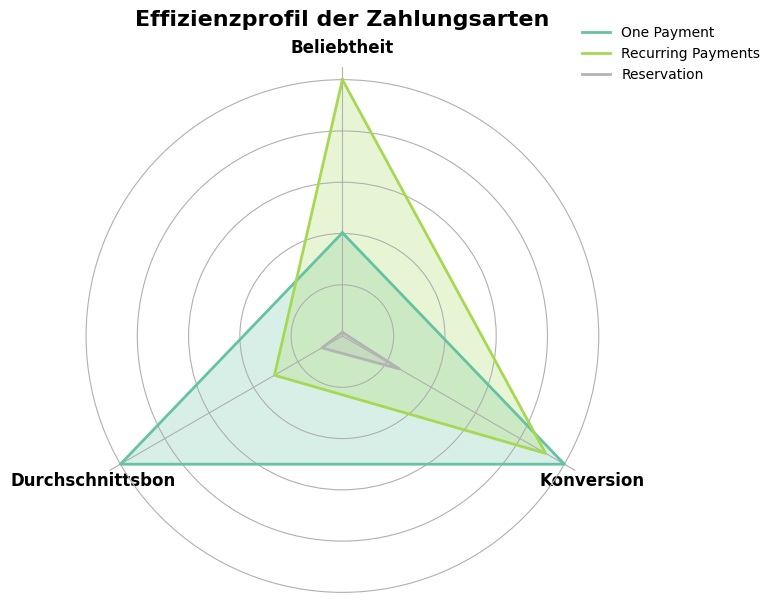


📌 ANALYTISCHE SCHLUSSFOLGERUNG:
--------------------------------------------------------------------------------------------------
1. Zahlungsanalyse (Netzdiagramm / Radar-Chart)
Dieses Diagramm beantwortet die Frage nach dem Einfluss der Zahlungsart auf den Erfolg:

Recurring Payments (Abo-Zahlungen/Wiederkehrend): Der Beliebtheitsführer. Die meisten Kunden wählen diesen Weg. Beim Durchschnittsbon und der Konversion liegt dieser Typ jedoch hinter der Einmalzahlung zurück.

One Payment (Einmalzahlung): Das "Premium"-Segment. Es weist den höchsten Durchschnittsbon und eine hervorragende Konversion auf. Kunden, die bereit sind, den gesamten Betrag auf einmal zu zahlen, sind die loyalsten und profitabelsten Kunden.

Reservation (Reservierung): Im Diagramm stellt dies den kleinen grauen Bereich in der Mitte dar. Das bedeutet, dass Reservierungen kaum Einfluss auf den Gesamtumsatz und die Beliebtheit haben.

Fazit: Für mehr kurzfristigen Gewinn gilt es, One Payment zu fördern. Für mehr Rei

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Nach Zahlungsart gruppieren
radar_df = deals.groupby('Payment Type').agg(
    Count=('Successful Deal', 'count'),
    CR=('Successful Deal', 'mean'),
    AvgCheck=('Initial Amount Paid', 'mean')
).reset_index()

# Daten skalieren: Jeden Wert durch das Maximum teilen, damit alle Indikatoren in ein gemeinsames Raster passen
for col in ['Count', 'CR', 'AvgCheck']:
    radar_df[col] = radar_df[col] / radar_df[col].max()

labels = ['Beliebtheit', 'Konversion', 'Durchschnittsbon']
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Kreis schließen

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

colors = plt.colormaps['Set2'].resampled(len(radar_df))

for i, row in radar_df.iterrows():
    values = [row['Count'], row['CR'], row['AvgCheck']]
    values += values[:1] # Werte schließen
    
    ax.plot(angles, values, linewidth=2, label=row['Payment Type'], color=colors(i))
    ax.fill(angles, values, color=colors(i), alpha=0.25)

# 3. Achsen- und Stil-Einstellungen
ax.set_theta_offset(np.pi / 2) # Oben beginnen
ax.set_theta_direction(-1)     # Im Uhrzeigersinn verlaufen
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=12, fontweight='bold')

# Skala und überflüssige Ränder entfernen
ax.set_yticklabels([])
ax.spines['polar'].set_visible(False)

plt.title('Effizienzprofil der Zahlungsarten', size=16, fontweight='bold', pad=30)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), frameon=False)
plt.tight_layout()
plt.show()

print("""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
1. Zahlungsanalyse (Netzdiagramm / Radar-Chart)
Dieses Diagramm beantwortet die Frage nach dem Einfluss der Zahlungsart auf den Erfolg:

Recurring Payments (Abo-Zahlungen/Wiederkehrend): Der Beliebtheitsführer. Die meisten Kunden wählen diesen Weg. Beim Durchschnittsbon und der Konversion liegt dieser Typ jedoch hinter der Einmalzahlung zurück.

One Payment (Einmalzahlung): Das "Premium"-Segment. Es weist den höchsten Durchschnittsbon und eine hervorragende Konversion auf. Kunden, die bereit sind, den gesamten Betrag auf einmal zu zahlen, sind die loyalsten und profitabelsten Kunden.

Reservation (Reservierung): Im Diagramm stellt dies den kleinen grauen Bereich in der Mitte dar. Das bedeutet, dass Reservierungen kaum Einfluss auf den Gesamtumsatz und die Beliebtheit haben.

Fazit: Für mehr kurzfristigen Gewinn gilt es, One Payment zu fördern. Für mehr Reichweite und Masse sollte das Abo-System (Recurring) ausgebaut werden.
--------------------------------------------------------------------------------------------------
""")

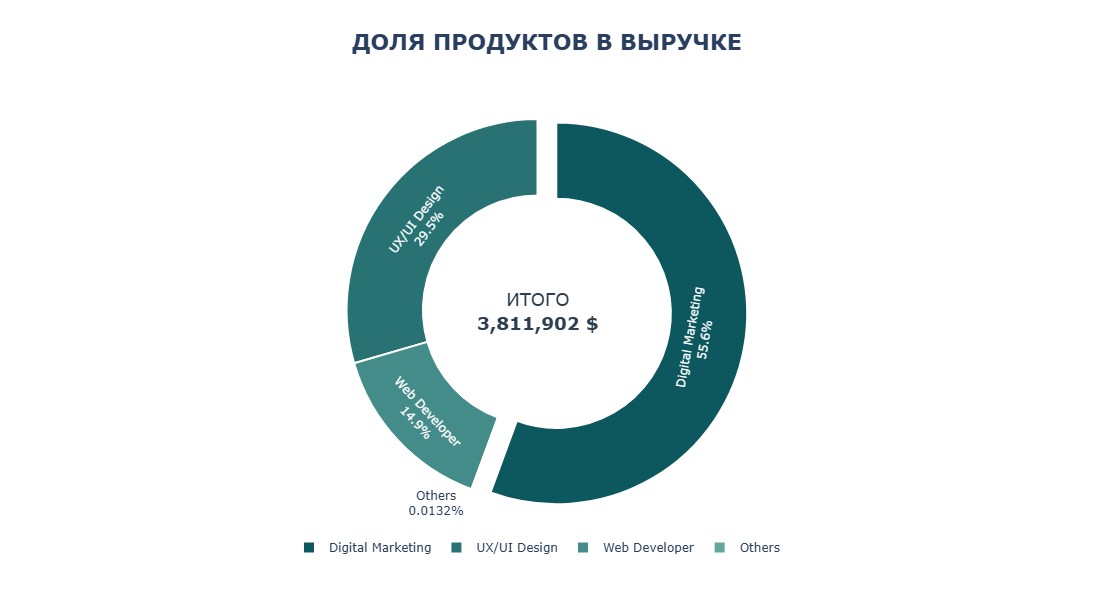

In [17]:
prod_data = deals[deals['Initial Amount Paid'] > 0].copy()
prod_data = prod_data.groupby('Product')['Initial Amount Paid'].sum().sort_values(ascending=False).reset_index()

total_revenue = prod_data['Initial Amount Paid'].sum()
threshold = total_revenue * 0.02

main_prods = prod_data[prod_data['Initial Amount Paid'] >= threshold].copy()
others_val = prod_data[prod_data['Initial Amount Paid'] < threshold]['Initial Amount Paid'].sum()

if others_val > 0:
    others_row = pd.DataFrame({'Product': ['Others'], 'Initial Amount Paid': [others_val]})
    plot_data = pd.concat([main_prods, others_row], ignore_index=True)
else:
    plot_data = main_prods

fig_prod = go.Figure(data=[go.Pie(
    labels=plot_data['Product'],
    values=plot_data['Initial Amount Paid'],
    hole=0.6,
    pull=[0.1] + [0] * (len(plot_data) - 1),
    marker=dict(
        
        colors=px.colors.sequential.Mint[::-1],
        line=dict(color='#ffffff', width=2)
    ),
    textinfo='percent+label',
    hoverinfo='label+value+percent',
    hovertemplate="<b>%{label}</b><br>Выручка: %{value:,.0f} $<br>Доля: %{percent}<extra></extra>"
)])


fig_prod.update_layout(
    title=dict(text='<b>ДОЛЯ ПРОДУКТОВ В ВЫРУЧКЕ</b>', x=0.5, font_size=22),
    annotations=[dict(
        text=f'ИТОГО<br><b>{int(total_revenue):,} $</b>', 
        x=0.5, y=0.5, 
        font_size=18, 
        showarrow=False,
        font_color='#2c3e50'
    )],
    height=600,
    template='plotly_white',
    showlegend=True,
    legend=dict(orientation="h", yanchor="bottom", y=-0.1, xanchor="center", x=0.5)
)

fig_prod.show()

In [30]:
print("""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Umsatzspitzenreiter: Digital Marketing — bringt über 55 % des Gesamtertrags (2,1 Mio. $+).
Dies ist das Hauptzugpferd unter den Produkten. Der maximale Return on Investment (ROI) konzentriert sich genau hier.

🎨 Stabile Nachfrage: UX/UI Design und Web Developer — erbringen zusammen etwa 45 % des Umsatzes.
Wichtige Segmente, die für die Umsatzdiversifizierung sorgen und die Nachfrage nach IT-Schulungen abdecken.

💎 Zahlungseffizienz: One Payment — der Qualitätsmaßstab.
Trotz der Beliebtheit von Ratenzahlungen bietet die Einmalzahlung die beste Konversion und den höchsten Bon.

💡 Fazit & Strategie:
Fokussierung des Budgets auf Digital Marketing für das Gewinnwachstum sowie gezielte Förderung von One Payment zur Maximierung der Qualität.
--------------------------------------------------------------------------------------------------

""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
🏆 Umsatzspitzenreiter: Digital Marketing — bringt über 55 % des Gesamtertrags (2,1 Mio. $+).
Dies ist das Hauptzugpferd unter den Produkten. Der maximale Return on Investment (ROI) konzentriert sich genau hier.

🎨 Stabile Nachfrage: UX/UI Design und Web Developer — erbringen zusammen etwa 45 % des Umsatzes.
Wichtige Segmente, die für die Umsatzdiversifizierung sorgen und die Nachfrage nach IT-Schulungen abdecken.

💎 Zahlungseffizienz: One Payment — der Qualitätsmaßstab.
Trotz der Beliebtheit von Ratenzahlungen bietet die Einmalzahlung die beste Konversion und den höchsten Bon.

💡 Fazit & Strategie:
Fokussierung des Budgets auf Digital Marketing für das Gewinnwachstum sowie gezielte Förderung von One Payment zur Maximierung der Qualität.
--------------------------------------------------------------------------------------------------




### Geografische Analyse


1. Analysieren Sie die geografische Verteilung der Deals nach Städten.


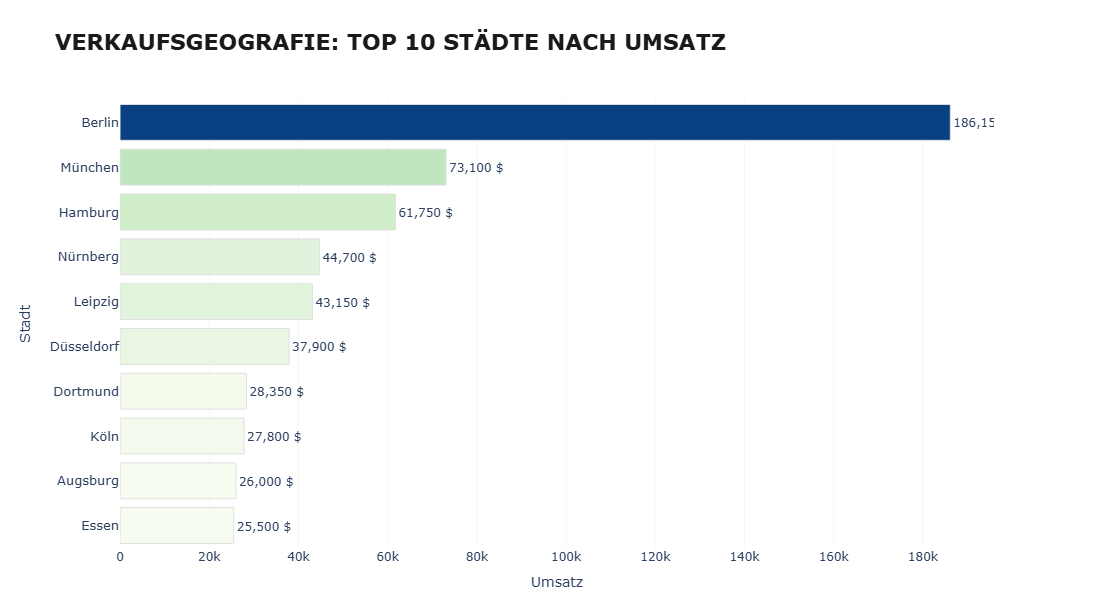

In [31]:
city_data = deals.dropna(subset=['City']).copy()
city_data = city_data[city_data['City'] != 'Unknown'] 

city_analysis = city_data.groupby('City').agg(
    Revenue=('Initial Amount Paid', 'sum')
).reset_index()

# TOP 10 nehmen und für das Diagramm sortieren
top_cities = city_analysis.sort_values('Revenue', ascending=True).tail(10)


fig_city = px.bar(
    top_cities, 
    x='Revenue', 
    y='City', 
    orientation='h',
    text='Revenue', # Umsatz direkt auf den Balken anzeigen
    color='Revenue', # Farbskala hängt vom Umsatz ab
    color_continuous_scale='GnBu', 
    labels={'Revenue': 'Umsatz', 'City': 'Stadt'}
)


fig_city.update_traces(
    texttemplate='%{text:,.0f} $', # Zahlenformat mit Tausendertrennzeichen und $-Zeichen
    textposition='outside',        # Beschriftungen außerhalb der Balken
    marker_line_color='rgb(224, 224, 224)',
    marker_line_width=1,
    hovertemplate="<b>%{y}</b><br>Umsatz: %{x:,.0f} $<extra></extra>"
)

fig_city.update_layout(
    title={
        'text': "<b>VERKAUFSGEOGRAFIE: TOP 10 STÄDTE NACH UMSATZ</b>",
        'x': 0.05, # Links ausgerichtet
        'font': {'size': 22, 'color': '#1a1a1a'}
    },
    xaxis=dict(
        showgrid=True, 
        gridcolor='rgba(224, 224, 224, 0.3)', 
        gridwidth=1,
        zeroline=False
    ),
    yaxis=dict(
        categoryorder='total ascending', # Richtige Reihenfolge garantieren
        tickfont=dict(size=13, shadow="bold")
    ),
    plot_bgcolor='white', 
    paper_bgcolor='white',
    coloraxis_showscale=False, 
    height=600,
    margin=dict(l=120, r=100, t=100, b=50) # Ränder für lange Stadtnamen
)

fig_city.show()

In [32]:
print("""
📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
👑 Berlin — das Herz des Umsatzes: Mit einem Umsatz von 186.150 $ und 78 Deals bringt die Hauptstadt 2,5-mal mehr ein als der nächste Konkurrent.
Dies ist Ihr Hauptmarkt mit der höchsten Dichte an erfolgreichen Zahlungen.

🏛️ Die „Großen Drei“: Berlin, München (73.100 $) und Hamburg (61.750 $) bilden das Kerngerüst des Geschäfts. Diese drei Städte sind Ihre Zonen
maximaler Konzentration.

⚖️ Qualität versus Quantität:
Nürnberg zeigt ein hervorragendes Ergebnis: 44.700 $ bei nur 9 Deals. Dies signalisiert den höchsten durchschnittlichen Bon unter den Top-Städten.
Leipzig hingegen erzielte bei 18 Deals (doppelt so viele wie in Nürnberg) mit 43.150 $ weniger Umsatz.

🌐 Gleichmäßige Abdeckung: Die Städte der zweiten Hälfte der Liste (Düsseldorf, Dortmund, Köln) folgen mit geringem Abstand zueinander 
im Bereich von 25k – 38k. Dies zeigt, dass das Produkt landesweit gefragt ist und nicht nur in ein bis zwei Megacitys.
--------------------------------------------------------------------------------------------------

""")


📌 ANALYTISCHES FAZIT:
--------------------------------------------------------------------------------------------------
👑 Berlin — das Herz des Umsatzes: Mit einem Umsatz von 186.150 $ und 78 Deals bringt die Hauptstadt 2,5-mal mehr ein als der nächste Konkurrent.
Dies ist Ihr Hauptmarkt mit der höchsten Dichte an erfolgreichen Zahlungen.

🏛️ Die „Großen Drei“: Berlin, München (73.100 $) und Hamburg (61.750 $) bilden das Kerngerüst des Geschäfts. Diese drei Städte sind Ihre Zonen
maximaler Konzentration.

⚖️ Qualität versus Quantität:
Nürnberg zeigt ein hervorragendes Ergebnis: 44.700 $ bei nur 9 Deals. Dies signalisiert den höchsten durchschnittlichen Bon unter den Top-Städten.
Leipzig hingegen erzielte bei 18 Deals (doppelt so viele wie in Nürnberg) mit 43.150 $ weniger Umsatz.

🌐 Gleichmäßige Abdeckung: Die Städte der zweiten Hälfte der Liste (Düsseldorf, Dortmund, Köln) folgen mit geringem Abstand zueinander 
im Bereich von 25k – 38k. Dies zeigt, dass das Produkt landesweit gefra